# 2. Random matrix theory: how much of a correlation matrix is real?

For $N$ assets observed over $T$ days, the sample correlation matrix has $N(N-1)/2$ entries estimated from $NT$ numbers. When $q = N/T$ is not small, the matrix is dominated by sampling noise.

Random matrix theory describes this noise exactly. If returns were independent, the eigenvalues of the sample correlation matrix would follow the **Marchenko-Pastur** density

$$\rho(\lambda) = \frac{\sqrt{(\lambda_+ - \lambda)(\lambda - \lambda_-)}}{2\pi q\,\lambda}, \qquad \lambda_\pm = (1 \pm \sqrt{q})^2 .$$

Although every true eigenvalue equals 1, the observed ones spread over $[\lambda_-, \lambda_+]$. Any eigenvalue inside that band is therefore compatible with pure noise. The idea comes from nuclear physics (Wigner) and was brought to finance by Laloux, Cizeau, Bouchaud and Potters (1999).

In [1]:
import sys
sys.path.insert(0, "..")  # make the `portfolio` package importable from the notebooks folder

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from portfolio import covariance as cov
from portfolio import load_prices, metrics, optimizer, rmt, run_backtest, sector_of, simulate_returns, split_benchmark, to_returns
from portfolio.backtest import equal_weight_strategy, max_sharpe_strategy, min_variance_strategy, risk_parity_strategy
from portfolio.plotting import use_style, BLUE, ORANGE, AQUA, YELLOW, MUTED, INK_SOFT, GRID

use_style()
pd.options.display.float_format = "{:.3f}".format

returns, benchmark = split_benchmark(to_returns(load_prices("../data/prices.csv")))
sectors = sector_of(returns.columns)
COLORS = {"Sample": ORANGE, "Ledoit-Wolf": AQUA, "RMT clipping": BLUE, "Equal weight": MUTED}
print(f"{returns.shape[1]} stocks, {len(returns):,} trading days, {returns.index[0]:%Y-%m-%d} to {returns.index[-1]:%Y-%m-%d}")

104 stocks, 4,242 trading days, 2010-01-05 to 2026-11-13


## 2.1 The law on pure noise

First a check with no finance at all: independent Gaussian returns.

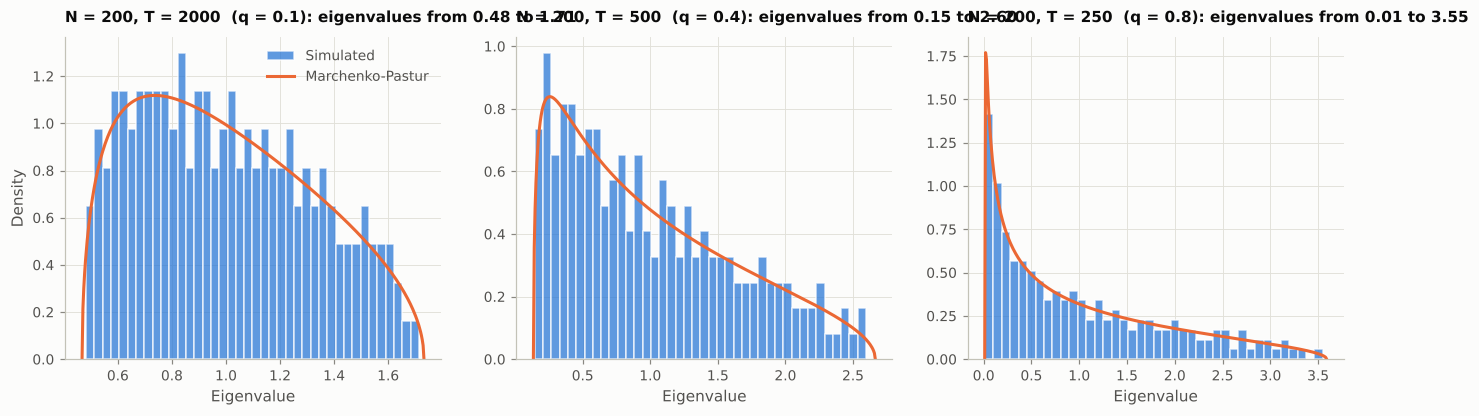

In [2]:
rng = np.random.default_rng(0)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, (n, t) in zip(axes, [(200, 2000), (200, 500), (200, 250)]):
    eigenvalues = np.linalg.eigvalsh(np.corrcoef(rng.standard_normal((t, n)), rowvar=False))
    low, high = rmt.marchenko_pastur_bounds(n / t)
    grid = np.linspace(low, high, 400)
    ax.hist(eigenvalues, bins=40, density=True, color=BLUE, alpha=0.75, edgecolor="white", label="Simulated")
    ax.plot(grid, rmt.marchenko_pastur_pdf(grid, n / t), color=ORANGE, label="Marchenko-Pastur")
    ax.set_title(f"N = {n}, T = {t}  (q = {n / t:.1f}): eigenvalues from {eigenvalues.min():.2f} to {eigenvalues.max():.2f}", fontsize=10)
    ax.set_xlabel("Eigenvalue")
axes[0].set_ylabel("Density"); axes[0].legend();

All the true eigenvalues are 1, yet with one year of data for 200 assets the estimated ones range from nearly 0 to more than 3.5. A portfolio optimiser reads the small ones as nearly risk-free combinations of assets. They are not.

## 2.2 The spectrum of real stock returns

In [3]:
window = 504
recent = returns.iloc[-window:]
correlation = np.corrcoef(recent.to_numpy(), rowvar=False)
spectrum = rmt.analyse_spectrum(correlation, window)
n = len(spectrum.eigenvalues)
print(f"N = {n}, T = {window}, q = {spectrum.q:.2f}")
print(f"Largest eigenvalues: {np.round(spectrum.eigenvalues[:8], 2)}")
print(f"Noise edge: {spectrum.noise_edge:.2f} -> {spectrum.n_signal} eigenvalues above it, carrying {spectrum.explained_by_signal:.0%} of the variance")
print(f"Largest eigenvalue alone: {spectrum.eigenvalues[0] / n:.0%} of the variance")

N = 104, T = 504, q = 0.21
Largest eigenvalues: [25.36 11.3   5.    4.39  3.25  2.79  2.24  1.91]
Noise edge: 1.60 -> 10 eigenvalues above it, carrying 58% of the variance
Largest eigenvalue alone: 24% of the variance


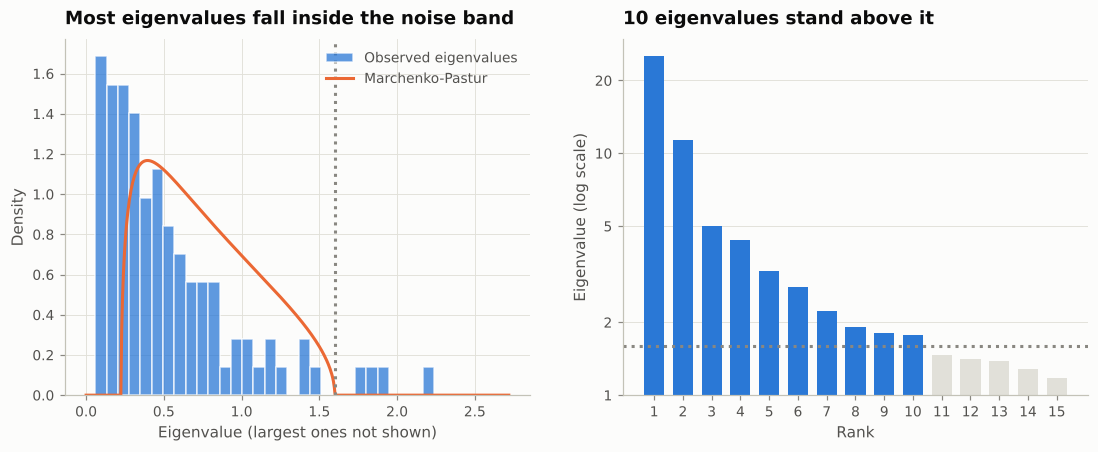

In [4]:
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4.2))
limit = 1.7 * spectrum.noise_edge
grid = np.linspace(1e-4, limit, 500)
left.hist(spectrum.eigenvalues[spectrum.eigenvalues <= limit], bins=30, density=True, color=BLUE, alpha=0.75, edgecolor="white",
          label="Observed eigenvalues")
left.plot(grid, rmt.marchenko_pastur_pdf(grid, spectrum.q, spectrum.bulk_variance), color=ORANGE, label="Marchenko-Pastur")
left.axvline(spectrum.noise_edge, color=MUTED, linestyle=":")
left.set_xlabel("Eigenvalue (largest ones not shown)"); left.set_ylabel("Density")
left.set_title("Most eigenvalues fall inside the noise band"); left.legend()

colors = [BLUE if value > spectrum.noise_edge else GRID for value in spectrum.eigenvalues[:15]]
right.bar(np.arange(1, 16), spectrum.eigenvalues[:15], color=colors, width=0.7)
right.axhline(spectrum.noise_edge, color=MUTED, linestyle=":")
right.set_yscale("log"); right.set_yticks([1, 2, 5, 10, 20], ["1", "2", "5", "10", "20"]); right.minorticks_off()
right.set_xticks(np.arange(1, 16)); right.grid(axis="x", visible=False)
right.set_xlabel("Rank"); right.set_ylabel("Eigenvalue (log scale)")
right.set_title(f"{spectrum.n_signal} eigenvalues stand above it");

The agreement with the noise law is approximate, not exact: real returns have fat tails and the true correlation structure is not flat below the edge, so the observed bulk is shifted towards small eigenvalues. The practical message holds: only a handful of eigenvalues are clearly distinguishable from noise.

The noise band used here is narrower than $(1+\sqrt q)^2$: the largest eigenvalue absorbs a share $\lambda_1/N$ of the total variance, and only the remainder is spread over the other modes.

## 2.3 What the significant eigenvectors are

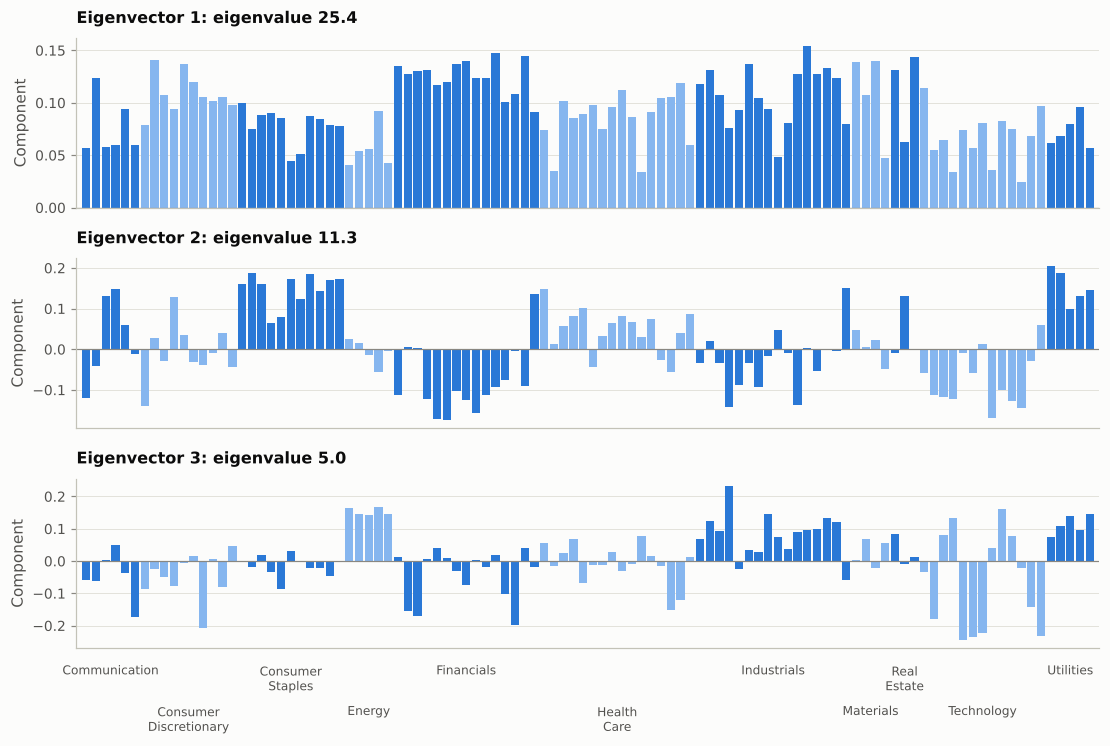

In [5]:
ordered = sectors.sort_values(kind="stable")
spectrum_sorted = rmt.analyse_spectrum(np.corrcoef(recent[ordered.index].to_numpy(), rowvar=False), window)
names = pd.unique(ordered.to_numpy())
shade = {name: (BLUE if i % 2 == 0 else "#86b6ef") for i, name in enumerate(names)}

fig, axes = plt.subplots(3, 1, figsize=(12, 7.2), sharex=True)
for rank, ax in enumerate(axes):
    vector = spectrum_sorted.eigenvectors[:, rank]
    vector = vector * np.sign(vector.sum())
    ax.bar(np.arange(n), vector, color=[shade[s] for s in ordered], width=0.85)
    ax.axhline(0, color=MUTED, linewidth=0.8); ax.grid(axis="x", visible=False); ax.set_ylabel("Component")
    ax.set_title(f"Eigenvector {rank + 1}: eigenvalue {spectrum_sorted.eigenvalues[rank]:.1f}", fontsize=10.5)
position = 0
for i, name in enumerate(names):
    size = int((ordered == name).sum())
    axes[-1].text(position + (size - 1) / 2, -0.10 if i % 2 == 0 else -0.34, name.replace(" ", "\n"),
                  transform=axes[-1].get_xaxis_transform(), ha="center", va="top", fontsize=8, color=INK_SOFT)
    position += size
axes[-1].set_xticks([]); axes[-1].set_xlim(-1, n); fig.subplots_adjust(hspace=0.3)

In [6]:
market = spectrum_sorted.eigenvectors[:, 0] * np.sign(spectrum_sorted.eigenvectors[:, 0].sum())
market_portfolio = recent[ordered.index] @ (market / market.sum())
print(f"All components of the first eigenvector have the same sign: {bool((market > 0).all())}")
if benchmark is not None:
    print(f"Correlation between the first eigen-portfolio and the S&P 500: {market_portfolio.corr(benchmark.reindex(market_portfolio.index)):.3f}")

participation = 1 / rmt.inverse_participation_ratio(spectrum_sorted.eigenvectors)
second = pd.Series(spectrum_sorted.eigenvectors[:, 1] * np.sign(spectrum_sorted.eigenvectors[:, 1].sum()), index=ordered.index)
by_sector = second.groupby(ordered).mean().sort_values()
print(f"Effective number of stocks in eigenvector 1: {participation[0]:.0f} of {n}; in a typical noise eigenvector: {np.median(participation[spectrum_sorted.n_signal:]):.0f}")
print("\nAverage component of eigenvector 2 by sector:")
by_sector.to_frame("mean component").T

All components of the first eigenvector have the same sign: True
Correlation between the first eigen-portfolio and the S&P 500: 0.768
Effective number of stocks in eigenvector 1: 76 of 104; in a typical noise eigenvector: 28

Average component of eigenvector 2 by sector:


sector,Financials,Technology,Industrials,Energy,Consumer Discretionary,Materials,Communication,Real Estate,Health Care,Consumer Staples,Utilities
mean component,-0.079,-0.075,-0.026,-0.007,-0.006,0.007,0.028,0.040,0.047,0.147,0.154


The first eigenvector is the **market**: every component has the same sign, so every stock moves with it. The second opposes defensive sectors (utilities, consumer staples, health care) to financials and technology. These are the collective modes of the system, much like normal modes in physics.

## 2.4 Cleaning the matrix

**Eigenvalue clipping** keeps the eigenvalues above the noise edge and replaces all the others by their average (so the trace is preserved). The eigenvectors are untouched.

In [7]:
cleaned = rmt.clip_eigenvalues(correlation, window)
before, after = np.linalg.eigvalsh(correlation), np.linalg.eigvalsh(cleaned)
print(f"Smallest eigenvalue: {before.min():.3f} -> {after.min():.3f}")
print(f"Condition number:    {before.max() / before.min():.0f} -> {after.max() / after.min():.0f}")
off = np.triu_indices(n, 1)
print(f"Correlation between raw and cleaned pairwise correlations: {np.corrcoef(correlation[off], cleaned[off])[0, 1]:.3f}")
print(f"Largest change in a pairwise correlation: {np.abs(correlation - cleaned)[off].max():.2f}")

Smallest eigenvalue: 0.059 -> 0.379
Condition number:    428 -> 66
Correlation between raw and cleaned pairwise correlations: 0.971
Largest change in a pairwise correlation: 0.35


## 2.5 Does cleaning bring the matrix closer to the truth?

With real data the true matrix is unknown. A simulation with a known covariance (one market factor, eight sectors, specific risk) answers the question exactly. For each estimator: the distance to the true matrix, and the *true* volatility of the minimum-variance portfolio built from the estimate.

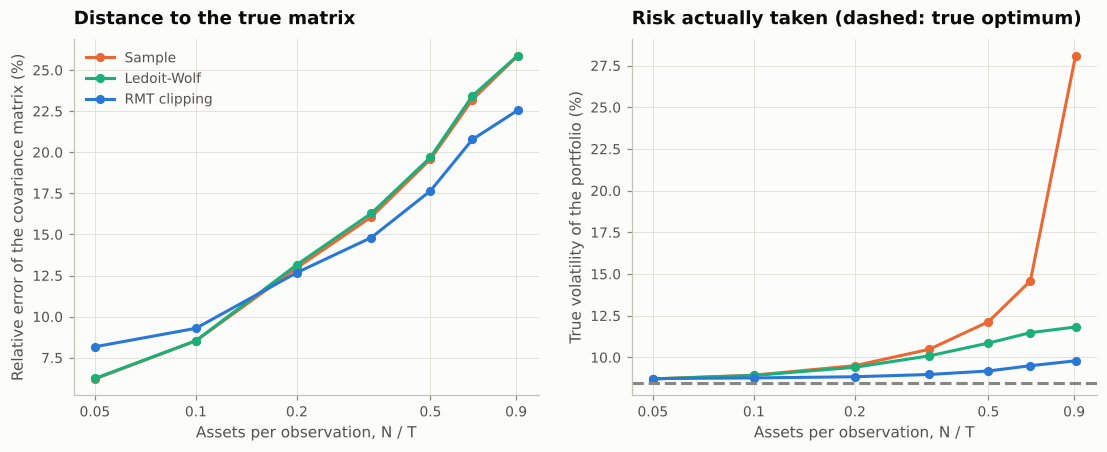

In [8]:
n_assets = 100
simulated, truth = simulate_returns(n_assets=n_assets, n_days=30_000, n_sectors=8, seed=0)
values = simulated.to_numpy()
rows = []
for t in [110, 150, 200, 300, 500, 1000, 2000]:
    for name, estimator in cov.ESTIMATORS.items():
        errors, vols, predicted = [], [], []
        for start in range(0, 30_000 - t, max(t, 1500)):
            estimate = estimator(values[start:start + t])
            w = optimizer.min_variance(estimate, long_only=False)
            errors.append(cov.frobenius_error(estimate, truth))
            vols.append(np.sqrt(252 * w @ truth @ w)); predicted.append(np.sqrt(252 * w @ estimate @ w))
        rows.append({"T": t, "q": n_assets / t, "estimator": name, "error": np.mean(errors),
                     "true_vol": np.mean(vols), "predicted_vol": np.mean(predicted)})
sim = pd.DataFrame(rows)
best = optimizer.min_variance(truth, long_only=False)
optimum = np.sqrt(252 * best @ truth @ best)

fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4.2))
for name, group in sim.groupby("estimator", sort=False):
    left.plot(group["q"], 100 * group["error"], marker="o", color=COLORS[name], label=name)
    right.plot(group["q"], 100 * group["true_vol"], marker="o", color=COLORS[name], label=name)
right.axhline(100 * optimum, color=MUTED, linestyle="--")
for ax in (left, right):
    ax.set_xscale("log"); ax.set_xticks([0.05, 0.1, 0.2, 0.5, 0.9], ["0.05", "0.1", "0.2", "0.5", "0.9"]); ax.minorticks_off()
    ax.set_xlabel("Assets per observation, N / T")
left.set_ylabel("Relative error of the covariance matrix (%)"); left.set_title("Distance to the true matrix"); left.legend()
right.set_ylabel("True volatility of the portfolio (%)"); right.set_title("Risk actually taken (dashed: true optimum)");

In [9]:
table = sim.pivot(index="q", columns="estimator", values=["predicted_vol", "true_vol"])[
    [("predicted_vol", "Sample"), ("true_vol", "Sample"), ("predicted_vol", "RMT clipping"), ("true_vol", "RMT clipping"),
     ("true_vol", "Ledoit-Wolf")]]
print(f"Volatility of the true minimum-variance portfolio: {optimum:.1%}")
table.style.format("{:.1%}")

Volatility of the true minimum-variance portfolio: 8.5%


Reading the table from bottom to top:

* with almost as many assets as observations, the sample matrix *predicts* a very low risk and *delivers* a very high one;
* both cleaned estimators stay close to the true optimum, eigenvalue clipping the closest on this factor-structured data;
* with many observations per asset the three estimators agree, and clipping is then slightly *further* from the true matrix: averaging the small eigenvalues removes some real structure. Cleaning is a bias-variance trade-off, worth it only when noise dominates.

## Summary

* The Marchenko-Pastur law gives the eigenvalue range that pure noise produces for a given $N/T$.
* In two years of data on about a hundred US stocks, roughly one eigenvalue in ten stands above that range. The first is the market, the following ones are sector modes.
* Cleaning the noisy eigenvalues leaves the large-scale structure untouched and removes the spurious low-risk directions an optimiser would exploit.